# 01 — Exploration des données DVF

**Objectif** : comprendre la structure des données DVF avant de modéliser, et décider des règles de nettoyage.

Questions traitées :
1. Quels types de ventes et de biens contient DVF ?
2. Comment une vente est-elle représentée (une ou plusieurs lignes) ?
3. Quelle surface utiliser : surface réelle ou surface Carrez ?
4. À quoi ressemblent les prix, et quelles valeurs sont aberrantes ?
5. Le prix dépend-il de la surface, du département, de l'année ?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# Style des graphiques : traits fins, grille discrète
BLEU = "#2a78d6"
COULEURS_DEP = {"18": "#2a78d6", "28": "#eb6834", "36": "#1baf7a",
                "37": "#eda100", "41": "#e87ba4", "45": "#008300"}
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})

## 1. Chargement des 30 fichiers (6 départements × 5 années)

In [2]:
DOSSIER_RAW = Path("..") / "data" / "raw"
fichiers = sorted(DOSSIER_RAW.glob("dvf_*.csv.gz"))

# Les codes (commune, département, parcelle) sont lus en texte pour garder les zéros initiaux
types = {"code_commune": str, "code_departement": str, "code_postal": str, "id_parcelle": str}
df = pd.concat([pd.read_csv(f, dtype=types, low_memory=False) for f in fichiers], ignore_index=True)
df["date_mutation"] = pd.to_datetime(df["date_mutation"])
df["annee"] = df["date_mutation"].dt.year

print(f"{len(fichiers)} fichiers, {len(df):,} lignes, {df.shape[1]} colonnes")

30 fichiers, 967,562 lignes, 41 colonnes


In [3]:
colonnes_utiles = ["id_mutation", "date_mutation", "nature_mutation", "valeur_fonciere",
                   "type_local", "surface_reelle_bati", "lot1_surface_carrez",
                   "nombre_pieces_principales", "nom_commune", "code_departement",
                   "longitude", "latitude"]
df[colonnes_utiles].head()

,id_mutation,date_mutation,nature_mutation,valeur_fonciere,type_local,surface_reelle_bati,lot1_surface_carrez,nombre_pieces_principales,nom_commune,code_departement,longitude,latitude
0,2021-265047,2021-01-05,Vente,1.00,NaN,NaN,NaN,NaN,Avord,18,NaN,NaN
1,2021-265048,2021-01-05,Vente,"3,500.00",NaN,NaN,NaN,NaN,Vignoux-sous-les-Aix,18,2.46,47.20
2,2021-265048,2021-01-05,Vente,"3,500.00",NaN,NaN,NaN,NaN,Vignoux-sous-les-Aix,18,2.46,47.20
3,2021-265049,2021-01-06,Vente,"65,000.00",Maison,40.00,NaN,1.00,Vierzon,18,2.07,47.22
4,2021-265050,2021-01-14,Vente,"2,500.00",NaN,NaN,NaN,NaN,Chârost,18,2.11,47.00


## 2. Types de mutations

In [4]:
df["nature_mutation"].value_counts().to_frame("lignes")

,lignes
nature_mutation,
Vente,923829
Vente en l'état futur d'achèvement,26643
Echange,11076
Adjudication,3061
Vente terrain à bâtir,2704
Expropriation,249


95 % des lignes sont des **ventes classiques**. Je ne garde que `Vente` :
- les **VEFA** (ventes sur plan) concernent du neuf, au prix différent de l'ancien ;
- les **adjudications** (enchères), **échanges** et **expropriations** ne reflètent pas un prix de marché ;
- les **ventes de terrain à bâtir** ne concernent pas des logements.

## 3. Types de biens

In [5]:
df["type_local"].value_counts(dropna=False).to_frame("lignes")

,lignes
type_local,
NaN,458563
Dépendance,221230
Maison,198489
Appartement,63221
Local industriel. commercial ou assimilé,26059


- `NaN` : lignes sans bâtiment (parcelles de terrain, jardins, terres agricoles).
- `Dépendance` : caves, garages, places de parking.
- Les **appartements** ne représentent que 6,5 % des lignes : il faudra bien les isoler.

## 4. Le piège : une vente répartie sur plusieurs lignes

Une ligne de DVF n'est **pas** une vente. Une vente (`id_mutation`) contient une ligne par bien ou par parcelle :
un appartement vendu avec sa cave et sa place de parking occupe donc plusieurs lignes.

In [6]:
lignes_par_vente = df.groupby("id_mutation").size()
print(f"{df['id_mutation'].nunique():,} ventes pour {len(df):,} lignes")
print(f"{(lignes_par_vente > 1).mean():.0%} des ventes occupent plusieurs lignes")

312,228 ventes pour 967,562 lignes
67% des ventes occupent plusieurs lignes


In [7]:
# Exemple : un appartement vendu avec une dépendance à Bourges
df.loc[df["id_mutation"] == "2021-265079",
       ["id_mutation", "date_mutation", "valeur_fonciere", "type_local",
        "surface_reelle_bati", "nombre_pieces_principales", "nom_commune"]]

,id_mutation,date_mutation,valeur_fonciere,type_local,surface_reelle_bati,nombre_pieces_principales,nom_commune
62,2021-265079,2021-01-19,"74,000.00",Appartement,52.00,3.00,Bourges
63,2021-265079,2021-01-19,"74,000.00",Dépendance,NaN,0.00,Bourges


In [8]:
# Le prix est-il réparti entre les lignes, ou répété sur chaque ligne ?
valeur_unique = df.groupby("id_mutation")["valeur_fonciere"].nunique(dropna=False) == 1
print(f"Prix identique sur toutes les lignes d'une vente : {valeur_unique.mean():.1%} des ventes")

Prix identique sur toutes les lignes d'une vente : 100.0% des ventes


**Le prix de la vente entière est recopié sur chaque ligne.** Conséquences :
- additionner `valeur_fonciere` sur les lignes compterait le même prix plusieurs fois ;
- si une vente contient **deux appartements**, le prix affiché est celui des deux : impossible de savoir combien vaut chacun.

Je compte donc, pour chaque vente, combien elle contient d'appartements, de maisons, de locaux et de dépendances.

In [9]:
ventes = df[df["nature_mutation"] == "Vente"]
composition = (
    ventes.assign(
        n_appartements=ventes["type_local"].eq("Appartement"),
        n_maisons=ventes["type_local"].eq("Maison"),
        n_locaux=ventes["type_local"].str.startswith("Local", na=False),
        n_dependances=ventes["type_local"].eq("Dépendance"),
    )
    .groupby("id_mutation")[["n_appartements", "n_maisons", "n_locaux", "n_dependances"]]
    .sum()
)

avec_appart = composition[composition["n_appartements"] >= 1]
un_seul = composition[(composition["n_appartements"] == 1)
                      & (composition["n_maisons"] == 0)
                      & (composition["n_locaux"] == 0)]

print(f"Ventes contenant au moins un appartement : {len(avec_appart):,}")
print(f"  dont plusieurs appartements (exclues)    : {(avec_appart['n_appartements'] >= 2).sum():,}")
print(f"Ventes d'un seul appartement (gardées)     : {len(un_seul):,}")
print(f"  dont avec au moins une dépendance        : {(un_seul['n_dependances'] > 0).mean():.0%}")

Ventes contenant au moins un appartement : 46,563
  dont plusieurs appartements (exclues)    : 5,468
Ventes d'un seul appartement (gardées)     : 40,072
  dont avec au moins une dépendance        : 82%


**Règle retenue** : une vente = **un seul appartement**, sans maison ni local commercial.
Les dépendances sont acceptées : 82 % des ventes en ont une, les exclure ferait perdre l'essentiel des données.
Leur présence pourra devenir une variable du modèle (« vendu avec cave ou parking »).

In [10]:
# Table de travail : une ligne par vente d'appartement
apparts = ventes[ventes["id_mutation"].isin(un_seul.index)
                 & ventes["type_local"].eq("Appartement")].copy()
apparts["a_dependance"] = apparts["id_mutation"].map(un_seul["n_dependances"] > 0)
print(f"{len(apparts):,} ventes d'appartements ; une ligne par vente : {apparts['id_mutation'].is_unique}")

40,072 ventes d'appartements ; une ligne par vente : True


## 5. Quelle surface : surface réelle ou surface Carrez ?

In [11]:
apparts[["surface_reelle_bati", "lot1_surface_carrez", "nombre_pieces_principales",
         "valeur_fonciere", "latitude"]].isna().mean().to_frame("part manquante")

,part manquante
surface_reelle_bati,0.00
lot1_surface_carrez,0.47
nombre_pieces_principales,0.00
valeur_fonciere,0.00
latitude,0.01


In [12]:
deux_surfaces = apparts.dropna(subset=["surface_reelle_bati", "lot1_surface_carrez"])
ratio = deux_surfaces["lot1_surface_carrez"] / deux_surfaces["surface_reelle_bati"]
ratio.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

count   21,370.00
mean         1.01
std          1.23
min          0.03
5%           0.84
25%          0.98
50%          1.00
75%          1.02
95%          1.10
max         99.59
dtype: float64

- La surface **Carrez** manque dans 47 % des ventes, la **surface réelle bâtie** jamais.
- Quand les deux existent, elles sont quasi égales (ratio médian 1,00).

**Je retiens `surface_reelle_bati`**, disponible partout. Je garde Carrez seulement comme contrôle.

## 6. Prix et valeurs aberrantes

In [13]:
apparts["prix_m2"] = apparts["valeur_fonciere"] / apparts["surface_reelle_bati"]
apparts[["valeur_fonciere", "surface_reelle_bati", "prix_m2"]].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])

,valeur_fonciere,surface_reelle_bati,prix_m2
count,"40,055.00","40,072.00","40,055.00"
mean,"122,167.89",57.98,"2,211.05"
std,"73,306.40",26.82,964.74
min,1.00,1.00,0.01
1%,"22,000.00",16.00,479.17
5%,"41,080.50",22.00,855.21
50%,"110,000.00",56.00,"2,135.00"
95%,"250,000.00",101.00,"3,750.00"
99%,"394,401.90",133.00,"4,625.00"
max,"1,390,000.00","1,400.00","28,958.33"


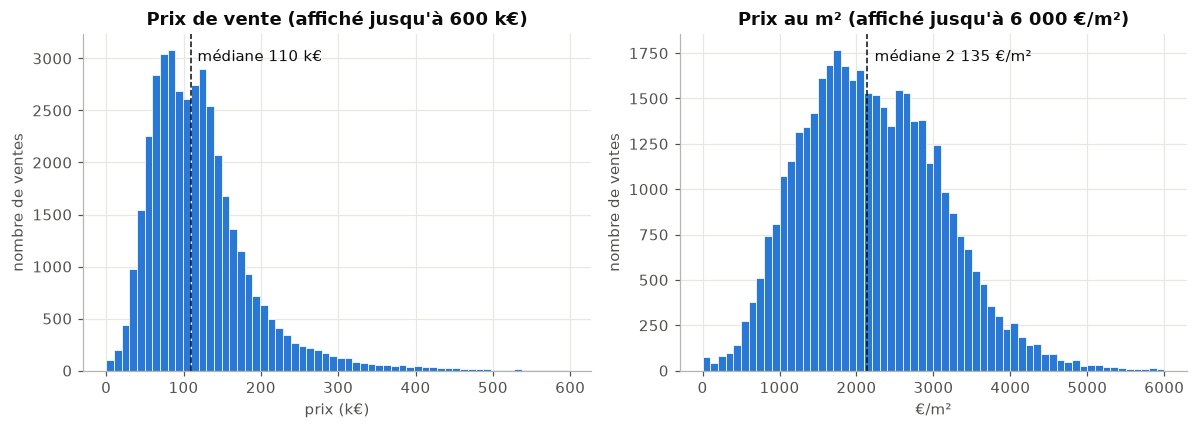

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

prix = apparts["valeur_fonciere"].dropna()
ax1.hist(prix[prix < 600_000] / 1000, bins=60, color=BLEU, edgecolor="white", linewidth=0.5)
ax1.axvline(prix.median() / 1000, color="#0b0b0b", linewidth=1, linestyle="--")
ax1.text(prix.median() / 1000 + 8, ax1.get_ylim()[1] * 0.92,
         f"médiane {prix.median() / 1000:.0f} k€", color="#0b0b0b")
ax1.set(title="Prix de vente (affiché jusqu'à 600 k€)", xlabel="prix (k€)", ylabel="nombre de ventes")

pm2 = apparts["prix_m2"].dropna()
ax2.hist(pm2[pm2 < 6000], bins=60, color=BLEU, edgecolor="white", linewidth=0.5)
ax2.axvline(pm2.median(), color="#0b0b0b", linewidth=1, linestyle="--")
ax2.text(pm2.median() + 100, ax2.get_ylim()[1] * 0.92,
         f"médiane {pm2.median():,.0f} €/m²".replace(",", " "), color="#0b0b0b")
ax2.set(title="Prix au m² (affiché jusqu'à 6 000 €/m²)", xlabel="€/m²", ylabel="nombre de ventes")

fig.tight_layout()
plt.show()

In [15]:
suspects = {
    "prix < 10 000 €": (apparts["valeur_fonciere"] < 10_000).sum(),
    "prix au m² < 300 €": (apparts["prix_m2"] < 300).sum(),
    "prix au m² > 8 000 €": (apparts["prix_m2"] > 8_000).sum(),
    "surface < 9 m²": (apparts["surface_reelle_bati"] < 9).sum(),
    "surface > 250 m²": (apparts["surface_reelle_bati"] > 250).sum(),
    "0 pièce principale": (apparts["nombre_pieces_principales"] == 0).sum(),
    "prix manquant": apparts["valeur_fonciere"].isna().sum(),
}
pd.Series(suspects).to_frame("ventes")

,ventes
prix < 10 000 €,103
prix au m² < 300 €,197
prix au m² > 8 000 €,13
surface < 9 m²,3
surface > 250 m²,7
0 pièce principale,17
prix manquant,17


- La distribution des prix est **asymétrique à droite** (longue queue vers les prix élevés) : une transformation logarithmique sera à tester en modélisation.
- Quelques centaines de ventes sont manifestement **aberrantes** : prix symboliques (jusqu'à 1 €),
  prix au m² irréalistes, surfaces impossibles (moins de 9 m², le minimum légal d'un logement).
  Elles représentent moins de 1 % des ventes et seront retirées au nettoyage.

## 7. Le prix dépend-il de la surface ?

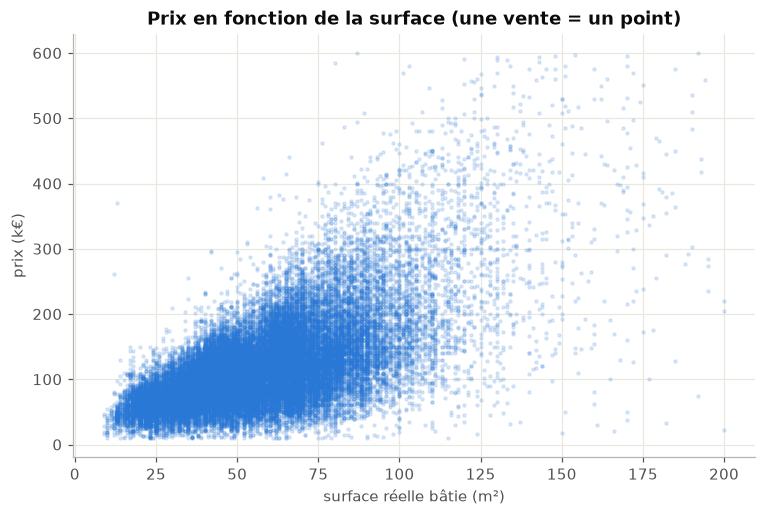

Corrélation surface / prix (toutes ventes) : 0.59
Corrélation surface / prix (sans extrêmes) : 0.62


In [16]:
vue = apparts[(apparts["valeur_fonciere"].between(10_000, 600_000))
              & (apparts["surface_reelle_bati"].between(9, 200))]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(vue["surface_reelle_bati"], vue["valeur_fonciere"] / 1000,
           s=4, alpha=0.15, color=BLEU, rasterized=True)
ax.set(title="Prix en fonction de la surface (une vente = un point)",
       xlabel="surface réelle bâtie (m²)", ylabel="prix (k€)")
plt.show()

corr = apparts[["surface_reelle_bati", "valeur_fonciere"]].corr().iloc[0, 1]
print(f"Corrélation surface / prix (toutes ventes) : {corr:.2f}")
print(f"Corrélation surface / prix (sans extrêmes) : "
      f"{vue[['surface_reelle_bati', 'valeur_fonciere']].corr().iloc[0, 1]:.2f}")

In [17]:
# Dispersion à surface comparable : appartements de 50 à 60 m²
prix_50_60 = apparts.loc[apparts["surface_reelle_bati"].between(50, 60), "valeur_fonciere"]
p10, p90 = prix_50_60.quantile([0.1, 0.9])
print(f"{len(prix_50_60):,} ventes de 50 à 60 m² : 80 % entre {p10:,.0f} € et {p90:,.0f} € "
      f"(rapport {p90 / p10:.1f})")

6,190 ventes de 50 à 60 m² : 80 % entre 55,000 € et 169,800 € (rapport 3.1)


La relation est **nettement croissante et à peu près linéaire** : une régression simple `prix ~ surface` a du sens.
Mais la dispersion est forte : à surface comparable (50 à 60 m²), les prix varient du simple au triple.
La surface seule ne suffira pas, d'où l'intérêt de la régression multiple (localisation, année…).

## 8. Le prix dépend-il du département et de l'année ?

In [18]:
noms_dep = {"18": "Cher", "28": "Eure-et-Loir", "36": "Indre",
            "37": "Indre-et-Loire", "41": "Loir-et-Cher", "45": "Loiret"}
mediane_m2 = apparts.pivot_table(index="code_departement", columns="annee",
                                 values="prix_m2", aggfunc="median").round(0).astype(int)
mediane_m2.index = [f"{c} {noms_dep[c]}" for c in mediane_m2.index]
mediane_m2

annee,2021,2022,2023,2024,2025
18 Cher,1287,1395,1429,1363,1450
28 Eure-et-Loir,2061,2206,2167,2093,2121
36 Indre,965,1154,1116,1102,1210
37 Indre-et-Loire,2484,2727,2714,2611,2643
41 Loir-et-Cher,1560,1750,1799,1815,1764
45 Loiret,2077,2233,2347,2157,2160


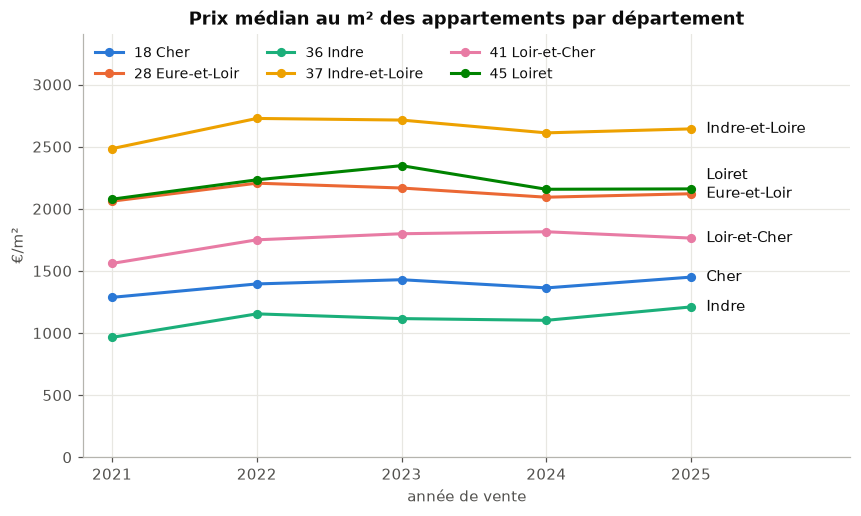

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
for dep, ligne in mediane_m2.iterrows():
    ax.plot(ligne.index, ligne.values, marker="o", markersize=5,
            color=COULEURS_DEP[dep.split()[0]], label=dep)

# Étiquettes en bout de ligne, écartées d'au moins 150 €/m² pour ne pas se chevaucher
derniere = mediane_m2.iloc[:, -1].sort_values()
positions = []
for valeur in derniere.values:
    positions.append(max(valeur, positions[-1] + 150) if positions else valeur)
for dep, y in zip(derniere.index, positions):
    ax.annotate(dep.split(" ", 1)[1], (mediane_m2.columns[-1], y), xytext=(10, 0),
                textcoords="offset points", va="center", color="#0b0b0b")
ax.set_xticks(mediane_m2.columns)
ax.set_xlim(mediane_m2.columns.min() - 0.2, mediane_m2.columns.max() + 1.1)
ax.set(title="Prix médian au m² des appartements par département",
       xlabel="année de vente", ylabel="€/m²")
ax.legend(loc="upper left", ncols=3, frameon=False, fontsize=9)
ax.set_ylim(0, mediane_m2.values.max() * 1.25)
plt.show()

In [20]:
apparts.groupby("annee").size().to_frame("ventes d'appartements")

,ventes d'appartements
annee,
2021,9359
2022,9052
2023,7402
2024,6634
2025,7625


- **Fort effet de la localisation** : un m² en Indre-et-Loire (Tours) vaut plus du double d'un m² dans l'Indre (Châteauroux).
  Le département (ou la commune, ou les coordonnées GPS) devra entrer dans le modèle.
- **Effet de l'année** : hausse de 2021 à 2022, puis stabilisation ou léger recul en 2024, au moment de la hausse des taux.
  Le nombre de ventes chute aussi (−29 % entre 2021 et 2024). L'année sera une variable du modèle.

## 9. Conclusions : règles de nettoyage pour le notebook 02

| Étape | Règle | Raison |
|---|---|---|
| Type de vente | garder `nature_mutation == "Vente"` | VEFA, enchères, échanges : autres logiques de prix |
| Unité d'analyse | une vente (`id_mutation`) = **un seul appartement**, sans maison ni local | le prix est recopié sur chaque ligne et couvre tous les biens de la vente |
| Dépendances | acceptées, signalées par `a_dependance` | 82 % des ventes en ont une |
| Surface | `surface_reelle_bati` | Carrez manque dans 47 % des cas |
| Valeurs aberrantes | retirer prix < 10 000 €, prix au m² hors [300 ; 8 000], surface hors [9 ; 250] m², 0 pièce | erreurs de saisie ou ventes hors marché |
| Variables candidates | surface, pièces, département / commune, latitude / longitude, année, dépendance | effets visibles dans l'exploration |

Base finale attendue : environ **40 000 ventes d'appartements** de 2021 à 2025.